# Financial Market Sentiment Analysis Engine

## Overview
This module provides an end-to-end Natural Language Processing (NLP) pipeline for fine-tuning a Transformer model (`distilbert-base-uncased`) on financial text data. It is designed to detect market sentiment (Bullish, Bearish, Neutral) from financial news and social media feeds, serving as the core analytical engine for a quantitative trading system.

## 1. Setup and Initialization
Centralized imports and configuration parameters for the training environment.

In [8]:
import os
import torch
import numpy as np
import pandas as pd
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, f1_score

MODEL_CHECKPOINT = "distilbert-base-uncased"
DATASET_NAME = "zeroshot/twitter-financial-news-sentiment"
SAVE_DIR = "../models"
MAX_SEQ_LENGTH = 64
BATCH_SIZE = 32
NUM_EPOCHS = 3
LEARNING_RATE = 2e-5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[SYSTEM] Hardware in use: {device.type.upper()}")

[SYSTEM] Hardware in use: CUDA


## 2. Data Ingestion and Preprocessing
Loading the financial dataset and converting textual data into machine-readable tensors.

In [9]:
print(f"[DATA] Loading dataset: {DATASET_NAME}")
dataset = load_dataset(DATASET_NAME)
train_dataset = dataset['train']
test_dataset = dataset['validation']


tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
def preprocess_text(examples: dict) -> dict:
    """
    Tokenizes input text, applying padding and truncation to maintain a uniform tensor length.
    
    Args:
        examples (dict): A dictionary containing the 'text' key with raw string data.
        
    Returns:
        dict: Tokenized input IDs and attention masks.
    """
    return tokenizer(
        examples["text"], 
        truncation=True, 
        padding="max_length", 
        max_length=MAX_SEQ_LENGTH
    )


print("[DATA] Tokenizing datasets...")
tokenized_train = train_dataset.map(preprocess_text, batched=True)
tokenized_test = test_dataset.map(preprocess_text, batched=True)
tokenized_datasets = {"train": tokenized_train, "test": tokenized_test}
print(f"[DATA] Preparation complete. Train size: {len(tokenized_train)} | Test size: {len(tokenized_test)}")

[DATA] Loading dataset: zeroshot/twitter-financial-news-sentiment
[DATA] Tokenizing datasets...
[DATA] Preparation complete. Train size: 9543 | Test size: 2388


## 3. Exploratory Data Analysis (EDA)
Before feeding the data into the Transformer model, it is crucial to understand the class distribution and the text length characteristics. This ensures we apply the correct preprocessing steps and evaluation metrics (such as Macro F1 for imbalanced datasets).

C:\Users\subki\AppData\Local\Temp\ipykernel_24828\3353246076.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x='sentiment', order=["BULLISH", "BEARISH", "NEUTRAL"], palette="viridis", ax=axes[0])


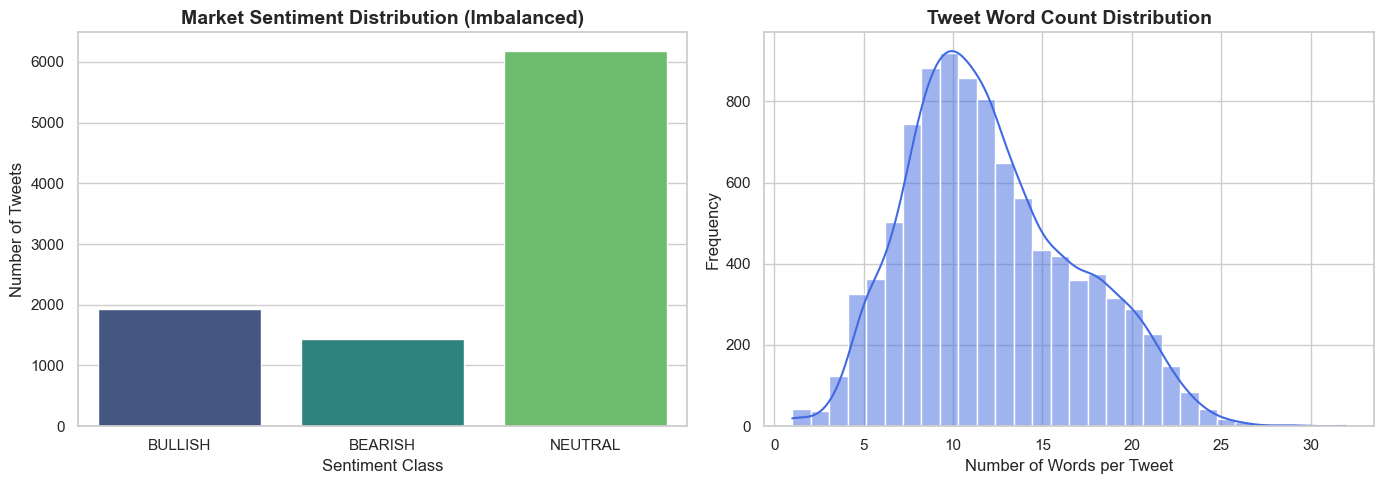

[EDA] Average words per tweet: 12.18
[EDA] Max words in a tweet: 32


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

df_train = pd.DataFrame(dataset['train'])
label_map = {0: "BEARISH", 1: "BULLISH", 2: "NEUTRAL"}
df_train['sentiment'] = df_train['label'].map(label_map)
df_train['word_count'] = df_train['text'].apply(lambda x: len(str(x).split()))
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Sentiment Class Distribution
sns.countplot(data=df_train, x='sentiment', order=["BULLISH", "BEARISH", "NEUTRAL"], palette="viridis", ax=axes[0])
axes[0].set_title("Market Sentiment Distribution (Imbalanced)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Sentiment Class")
axes[0].set_ylabel("Number of Tweets")

# Plot 2: Text Length Distribution
sns.histplot(data=df_train, x='word_count', bins=30, kde=True, color='royalblue', ax=axes[1])
axes[1].set_title("Tweet Word Count Distribution", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Number of Words per Tweet")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"[EDA] Average words per tweet: {df_train['word_count'].mean():.2f}")
print(f"[EDA] Max words in a tweet: {df_train['word_count'].max()}")

## 4. Model Architecture and Training Pipeline
Defining the classification layers, evaluation metrics, and executing the training loop.

In [11]:
id2label = {0: "BEARISH", 1: "BULLISH", 2: "NEUTRAL"}
label2id = {"BEARISH": 0, "BULLISH": 1, "NEUTRAL": 2}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT, 
    num_labels=len(id2label),
    id2label=id2label,
    label2id=label2id
)

def compute_metrics(eval_pred: tuple) -> dict:
    """
    Computes accuracy and macro F1 score for model evaluation.
    Macro F1 is utilized to penalize poor performance on minority classes (e.g., Bearish signals).
    """
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='macro')
    return {"accuracy": acc, "f1_macro": f1}

# Training Hyperparameters
training_args = TrainingArguments(
    output_dir=SAVE_DIR,
    eval_strategy="epoch",        
    save_strategy="epoch",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE, 
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,           
    weight_decay=0.01,
    load_best_model_at_end=True,
    report_to="none"
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["test"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

# Execute Training (Uncomment to train)
# print("[TRAINING] Initiating model fine-tuning...")
# trainer.train()

# Save Artifacts
# print(f"[SYSTEM] Saving production model to {SAVE_DIR}")
# trainer.save_model(SAVE_DIR)
# tokenizer.save_pretrained(SAVE_DIR)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 5. Inference Engine
Loading the fine-tuned model for production use to analyze real-time market data.

In [12]:
class MarketSentimentAnalyzer:
    """A production-ready class for running inference on the fine-tuned financial model."""
    
    def __init__(self, model_path: str):
        print(f"[INFERENCE] Loading model architecture from {model_path}...")
        self.tokenizer = AutoTokenizer.from_pretrained(model_path)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_path)
        self.model.eval() 
        
    def predict(self, text: str) -> dict:
        """Analyzes a financial text and returns the predicted market signal and confidence score."""
        inputs = self.tokenizer(
            text, 
            return_tensors="pt", 
            truncation=True, 
            max_length=MAX_SEQ_LENGTH
        )
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            
        probs = outputs.logits.softmax(dim=-1)
        pred_class = torch.argmax(probs, dim=-1).item()
        confidence = probs[0][pred_class].item()
        label = self.model.config.id2label[pred_class]
        
        return {
            "text": text,
            "signal": label,
            "confidence": round(confidence * 100, 2)
        }

# --- Production Simulation ---
if __name__ == "__main__":
    analyzer = MarketSentimentAnalyzer(SAVE_DIR)
    
    test_headlines = [
        "Tesla reports record-breaking revenue in Q4, beating analyst expectations by 20%.",
        "SEC sues the crypto exchange for selling unregistered securities, token price crashes.",
        "The company announced the date for its annual shareholder meeting.",
        "Google announces massive layoffs due to AI restructuring."
    ]
    
    print("\n[INFERENCE] Commencing Market Signal Simulation:")
    print("-" * 50)
    for headline in test_headlines:
        result = analyzer.predict(headline)
        print(f"News   : {result['text']}")
        print(f"Signal : {result['signal']} (Confidence: {result['confidence']}%)")
        print("-" * 50)

[INFERENCE] Loading model architecture from ../models...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


[INFERENCE] Commencing Market Signal Simulation:
--------------------------------------------------
News   : Tesla reports record-breaking revenue in Q4, beating analyst expectations by 20%.
Signal : BULLISH 🟢 (Confidence: 91.36%)
--------------------------------------------------
News   : SEC sues the crypto exchange for selling unregistered securities, token price crashes.
Signal : BEARISH 🔴 (Confidence: 81.33%)
--------------------------------------------------
News   : The company announced the date for its annual shareholder meeting.
Signal : NEUTRAL 🟡 (Confidence: 97.81%)
--------------------------------------------------
News   : Google announces massive layoffs due to AI restructuring.
Signal : BEARISH 🔴 (Confidence: 89.64%)
--------------------------------------------------
